In [1]:

# 1. Import required libraries
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator


In [2]:
# Dataset paths
train_path = r"D:\Downloads\DL DATASET\Brain tumor\Training"
test_path = r"D:\Downloads\DL DATASET\Brain tumor\Testing"


In [3]:
# Resize images and normalize pixel values
datagen = ImageDataGenerator(rescale=1./255)

In [4]:
train_data = datagen.flow_from_directory(
    train_path,
    target_size=(128, 128),
    batch_size=32,
    class_mode='categorical'
)
test_data = datagen.flow_from_directory(
    test_path,
    target_size=(128, 128),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

Found 2870 images belonging to 4 classes.
Found 394 images belonging to 4 classes.


In [5]:
model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(128,128,3)),
    MaxPooling2D(2,2),

    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(train_data.num_classes, activation='softmax')
])


C:\Users\19shi\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [6]:
# Compile the model
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


In [7]:
history = model.fit(
    train_data,
    epochs=10,
    validation_data=test_data
)

C:\Users\19shi\AppData\Roaming\Python\Python313\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
90/90 ━━━━━━━━━━━━━━━━━━━━ 56s 593ms/step - accuracy: 0.5780 - loss: 1.0264 - val_accuracy: 0.4924 - val_loss: 1.8960
Epoch 2/10
90/90 ━━━━━━━━━━━━━━━━━━━━ 56s 625ms/step - accuracy: 0.7739 - loss: 0.5421 - val_accuracy: 0.5102 - val_loss: 2.2020
Epoch 3/10
90/90 ━━━━━━━━━━━━━━━━━━━━ 57s 635ms/step - accuracy: 0.8707 - loss: 0.3351 - val_accuracy: 0.6320 - val_loss: 2.3239
Epoch 4/10
90/90 ━━━━━━━━━━━━━━━━━━━━ 60s 668ms/step - accuracy: 0.9122 - loss: 0.2258 - val_accuracy: 0.6599 - val_loss: 2.5343
Epoch 5/10
90/90 ━━━━━━━━━━━━━━━━━━━━ 60s 672ms/step - accuracy: 0.9286 - loss: 0.1761 - val_accuracy: 0.7081 - val_loss: 2.4258
Epoch 6/10
90/90 ━━━━━━━━━━━━━━━━━━━━ 59s 653ms/step - accuracy: 0.9491 - loss: 0.1390 - val_accuracy: 0.7310 - val_loss: 2.9063
Epoch 7/10
90/90 ━━━━━━━━━━━━━━━━━━━━ 55s 611ms/step - accuracy: 0.9634 - loss: 0.1067 - val_accuracy: 0.7234 - val_loss: 3.2407
Epoch 8/10
90/90 ━━━━━━━━━━━━━━━━━━━━ 83s 618ms/step - accuracy: 0.9718 - loss: 0.0878 - val_accu

In [8]:
# d. Estimating the model's performance

loss, accuracy = model.evaluate(test_data)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy * 100, "%")

13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 196ms/step - accuracy: 0.7259 - loss: 3.9193     
Test Loss: 3.919262647628784
Test Accuracy: 72.58883118629456 %


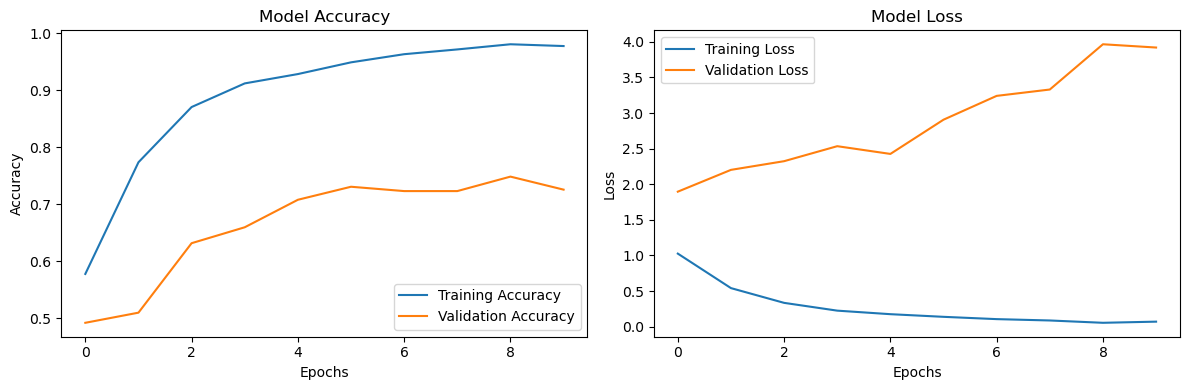

MemoryError: Unable to allocate 6.00 MiB for an array with shape (32, 128, 128, 3) and data type float32

In [18]:
# Plot training and validation accuracy
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Plot training and validation loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


images, labels = random.choice(list(test_data))
i = random.randint(0, len(images)-1)
image = images[i]

predicted = np.argmax(model.predict(image[None, ...], verbose=0))
actual = np.argmax(labels[i])

plt.imshow(image)
plt.title("Actual: " + class_names[actual] +
          "\nPredicted: " + class_names[predicted])
plt.axis('off')
plt.show()

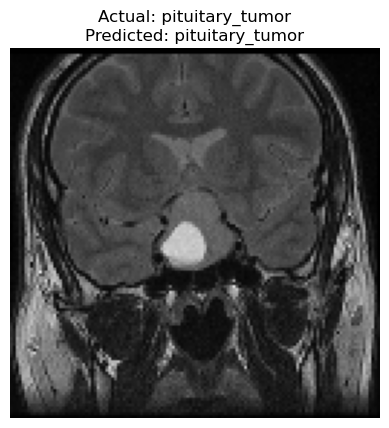

In [19]:
# Select a random batch
batch = random.choice(range(len(test_data)))
images, labels = test_data[batch]
class_names = list(train_data.class_indices.keys())
# Select one image from the batch
i = random.randint(0, len(images) - 1)
image = images[i]

predicted = np.argmax(model.predict(image[None, ...], verbose=0))
actual = np.argmax(labels[i])

plt.imshow(image)
plt.title("Actual: " + class_names[actual] +
          "\nPredicted: " + class_names[predicted])
plt.axis('off')
plt.show()